# Other BVOC check: how much of the MEGAN signal is not ISOP or MTERP?

The fBVOC runs keep only ISOP and MTERP and switch off every other MEGAN compound. This notebook sums the CLM `MEG_*` emissions in CTRL and LCC and asks two questions:

1. **Share of total:** what fraction of the emissions are "other" compounds? This sets the size of what the fBVOC runs remove.
2. **Share of the change:** what fraction of ΔE (LCC − CTRL) comes from "other" compounds? This is what an ISOP/MTERP-only BVOC definition misses.

Both are computed by **mass** and by **OH reactivity** (emitted moles × k_OH at 298 K). Mass alone overweights slow reactants such as methanol and CO.

**Inputs:** CLM h0 monthly files only. `MEG_<name>` fields are active by default, kg m⁻² s⁻¹, gridcell average with lake and urban set to 0 (CTSM `VOCEmissionMod.F90`, NorESM tag `release-clm5.0.14-Nor_v1.0.7`).

## Conclusions:

How to read your results

Read the land ≥ 45°N table. That is where the land cover changes.

Land ≥ 45°N	“Other” share of CTRL emissions	“Other” share of LCC − CTRL change
By mass	56 %	35 %
By OH reactivity	15 %	4 %
By mass, “Other” looks large. This is mostly slow-reacting mass (b). The OH reactivity column drops “Other” from 56 % to 15 % of emissions, which only happens if the bulk of that mass reacts slowly with OH. I’d guess methanol and CO (c), but I can’t see the per-compound split in your HTML.
By OH reactivity, the land-cover change is ISOP + MTERP. They make up 96 % of the change (86 % ISOP, 10 % MTERP). “Other” adds 4 %, spread thinly over C3H6, BIGENE, CH3OH and CH3CHO, as your per-species bar chart shows (a).
What fBVOC removes is a different, bigger number. Switching the other compounds off takes away about 15 % of emitted OH reactivity in both CTRL and LCC. That is the D1 artifact, and it is not negligible. Most of it should cancel in the BVOC contrast, because the LCC change barely moves the other compounds (b, this assumes linearity).

Two caveats. OH reactivity ignores ozonolysis, so it underweights BCARY. And the ≥ 45°N box also includes cells where the land cover doesn’t change, which dilutes all the Δ values (b).

The global table needs care

Globally, the ISOP Δ is −7.6 Tg/yr, while north of 45°N it is +0.43 Tg/yr (a). So about 8 Tg/yr of decrease comes from outside the region where the land cover changes. The global “share of Δ” values are therefore not meaningful, which is why the global “Other” share comes out at −17 %.

My reading (b): the runs are nudged on winds only, so temperature and clouds can still differ between LCC and CTRL. Isoprene emissions respond strongly to temperature: roughly 0.1–0.2 K of tropical warming or cooling would be enough. Whether this is noise or a real remote response, I can’t tell from these numbers. The new figure’s year-to-year spread is the first test.

In [1]:
import glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- EDIT
ARCHIVE = "/cluster/work/users/adelez/archive"
RUNS = {
    "CTRL_PD": "NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925",
    "LCC_PD":  "NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261005",
    # "CTRL_FUT": "NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20260925",
    # "LCC_FUT":  "NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261005",
}
PAIRS = [("CTRL_PD", "LCC_PD")]          # (reference, perturbed); add ("CTRL_FUT", "LCC_FUT")
SPINUP_MONTHS = 12                         # dropped at the start of each run
LAT_MIN_REGION = 45.0                      # second domain: land north of this latitude
T_REF, P_REF = 298.0, 101325.0             # for k_OH (surface conditions)
# ----------------------------------------------------------------------

def h0_files(case):
    files = sorted(glob.glob(f"{ARCHIVE}/{case}/lnd/hist/{case}.clm2.h0.*.nc"))
    if not files:
        raise FileNotFoundError(f"No CLM h0 files for {case}")
    return files

## Compound table

Taken from your `megan_specifier`. Molar masses are standard values I typed in (not read from the model). The CAM species decides which k_OH applies.

In [2]:
# MEGAN name: (CAM species, molar mass g/mol)
C10H16, C15H24 = 136.23, 204.35
COMPOUNDS = {
    "isoprene": ("ISOP", 68.12),
    **{n: ("MTERP", C10H16) for n in [
        "pinene_a", "carene_3", "thujene_a", "terpinolene", "bornene", "fenchene_a",
        "ocimene_al", "pinene_b", "sabinene", "camphene", "limonene", "phellandrene_a",
        "terpinene_g", "terpinene_a", "phellandrene_b", "myrcene", "ocimene_t_b", "ocimene_c_b"]},
    "2met_styrene": ("MTERP", 118.18), "cymene_p": ("MTERP", 134.22), "cymene_o": ("MTERP", 134.22),
    **{n: ("BCARY", C15H24) for n in [
        "caryophyllene_b", "bergamotene_a", "bisabolene_b", "farnescene_b", "humulene_a"]},
    "methanol": ("CH3OH", 32.04), "ethanol": ("C2H5OH", 46.07), "formaldehyde": ("CH2O", 30.03),
    "acetaldehyde": ("CH3CHO", 44.05), "acetic_acid": ("CH3COOH", 60.05), "acetone": ("CH3COCH3", 58.08),
    "formic_acid": ("HCOOH", 46.03), "hydrogen_cyanide": ("HCN", 27.03), "carbon_monoxide": ("CO", 28.01),
    "ethane": ("C2H6", 30.07), "ethene": ("C2H4", 28.05), "propane": ("C3H8", 44.10), "propene": ("C3H6", 42.08),
    "pentane": ("BIGALK", 72.15), "hexane": ("BIGALK", 86.18), "heptane": ("BIGALK", 100.20),
    "tricyclene": ("BIGALK", C10H16), "butene": ("BIGENE", 56.11), "toluene": ("TOLUENE", 92.14),
}
assert len(COMPOUNDS) == 46

def group(cam):
    """Three-way split used in the summary."""
    return cam if cam in ("ISOP", "MTERP") else "Other"

## k_OH at 298 K

Rate expressions copied from `pp_tropstrat_mam_oslo/chem_mech.in` and `mozart/mo_usrrxt.F90` in your CAM fork (branch `new-case-set`). CAM convention: Arrhenius `A, B` means k = A·exp(B/T); Troe `k0, n0, kinf, ninf, fc` uses (300/T)ⁿ.

Checked against the `chem_mech.in` from your run: it is identical to `pp_tropstrat_mam_oslo/chem_mech.in` in the fork, apart from blank lines and trailing spaces.

In [3]:
def arr(A, B=0.0, T=T_REF):
    return A * np.exp(B / T)

def troe(k0A, n0, kiA, ni, fc, T=T_REF, P=P_REF):
    M = P / (1.380649e-23 * T) * 1e-6                       # molecules cm-3
    k0, ki = k0A * (300 / T) ** n0 * M, kiA * (300 / T) ** ni
    return k0 / (1 + k0 / ki) * fc ** (1 / (1 + np.log10(k0 / ki) ** 2))

def k_co(T=T_REF, P=P_REF):                                  # CO_OH_M + usr_CO_OH_b
    M = P / (1.380649e-23 * T) * 1e-6
    ki, ko = 2.1e9 * (T / 300) ** 6.1, 1.5e-13
    t1 = ko / (ki / M)
    b = ko / (1 + t1) * 0.6 ** (1 / (1 + np.log10(t1) ** 2))
    return troe(5.9e-33, 1, 1.1e-12, -1.3, 0.6, T, P) + b

K_OH = {                                   # cm3 molecule-1 s-1; chem_mech.in reaction label
    "ISOP":     arr(2.54e-11, 410),        # ISOP_OH
    "MTERP":    arr(1.2e-11, 440),         # MTERP_OH
    "BCARY":    arr(2e-10),                # BCARY_OH
    "CH3OH":    arr(2.9e-12, -345),        # CH3OH_OH
    "C2H5OH":   arr(6.9e-12, -230),        # C2H5OH_OH
    "CH2O":     arr(5.5e-12, 125),         # CH2O_OH
    "CH3CHO":   arr(4.63e-12, 350),        # CH3CHO_OH
    "CH3COOH":  arr(7e-13),                # CH3COOH_OH
    "CH3COCH3": 3.82e-11 * np.exp(-2000 / T_REF) + 1.33e-13,   # usr_CH3COCH3_OH
    "HCOOH":    arr(4e-13),                # HCOOH_OH
    "HCN":      troe(4.28e-33, 0, 9.3e-15, -4.42, 0.8),        # HCN_OH
    "CO":       k_co(),                    # CO_OH_M + usr_CO_OH_b
    "C2H6":     arr(7.66e-12, -1020),      # C2H6_OH
    "C2H4":     troe(8.6e-29, 3.1, 9e-12, 0.85, 0.48),         # tag_C2H4_OH
    "C3H8":     arr(8.7e-12, -615),        # C3H8_OH
    "C3H6":     troe(8e-27, 3.5, 3e-11, 0, 0.5),               # tag_C3H6_OH
    "BIGALK":   arr(3.5e-12),              # BIGALK_OH
    "BIGENE":   arr(5.4e-11),              # BIGENE_OH
    "TOLUENE":  arr(1.7e-12, 352),         # TOLUENE_OH
}
pd.Series(K_OH, name="k_OH(298 K)").map("{:.2e}".format).to_frame().T

,ISOP,MTERP,BCARY,CH3OH,C2H5OH,CH2O,CH3CHO,CH3COOH,CH3COCH3,HCOOH,HCN,CO,C2H6,C2H4,C3H8,C3H6,BIGALK,BIGENE,TOLUENE
k_OH(298 K),1.01e-10,5.25e-11,2.00e-10,9.11e-13,3.19e-12,8.37e-12,1.50e-11,7.00e-13,1.79e-13,4.00e-13,7.49e-15,2.37e-13,2.50e-13,8.07e-12,1.10e-12,2.87e-11,3.50e-12,5.40e-11,5.54e-12


## Annual totals per compound

In [4]:
def keep_meg(d):
    """Keep only the MEG_* fields, so files are concatenated along time and nothing else."""
    return d[[v for v in d.data_vars if v.startswith("MEG_")]]

def month_seconds(times):
    """Length of each monthly averaging interval, from the time stamps.

    CLM stamps monthly means at the end of the interval (e.g. 0001-02-01 for January).
    Shifting back one day lands inside the averaged month whether the stamp is the end
    or the middle of the interval; days_in_month then follows the model calendar."""
    idx = times.to_index()
    return xr.DataArray(np.asarray(idx.shift(-1, "D").days_in_month) * 86400.0,
                        dims="time", coords={"time": times})

def annual_totals(case):
    """Tg/yr per compound, global land and land north of LAT_MIN_REGION."""
    files = h0_files(case)
    ds = xr.open_mfdataset(files, combine="nested", concat_dim="time", preprocess=keep_meg)
    ds = ds.sortby("time")
    dup = ds.indexes["time"].duplicated()
    if dup.any():
        print(f"[{case}] dropping {dup.sum()} duplicated time stamps")
        ds = ds.isel(time=~dup)
    ds = ds.isel(time=slice(SPINUP_MONTHS, None))

    found = sorted(v[4:] for v in ds.data_vars)
    missing = sorted(set(COMPOUNDS) - set(found))
    extra = sorted(set(found) - set(COMPOUNDS))
    if missing or extra:
        print(f"[{case}] missing: {missing}  not in table: {extra}")

    with xr.open_dataset(files[0]) as f0:                               # static fields
        if f0["area"].attrs.get("units", "km^2") not in ("km^2", "km2"):
            raise ValueError(f"unexpected area units: {f0['area'].attrs.get('units')}")
        w = (f0["area"] * 1e6 * f0["landfrac"]).fillna(0).load()       # m2 of land
        lat = f0["lat"].load()

    sec = month_seconds(ds["time"])
    n_years = float(sec.sum()) / (365 * 86400)
    t = ds.indexes["time"]
    print(f"[{case}] {ds.time.size} months used, {t[0]} to {t[-1]} ({n_years:.2f} yr)")

    region = (lat >= LAT_MIN_REGION)
    year = xr.DataArray(np.asarray(t.shift(-1, "D").year), dims="time", coords={"time": ds["time"]})
    names = [n for n in found if n in COMPOUNDS]
    per_year = {"global": {}, "region": {}}                             # Tg per calendar year
    for name in names:
        flux = (ds[f"MEG_{name}"].fillna(0) * w * sec)                   # kg per month per cell
        for dom, f in (("global", flux), ("region", flux.where(region, 0))):
            per_year[dom][name] = (f.sum(("lat", "lon")).groupby(year).sum() / 1e9).to_series()
    per_year = {dom: pd.DataFrame(v) for dom, v in per_year.items()}
    complete = per_year["global"].index[pd.Series(year.values).value_counts().sort_index() == 12]
    per_year = {dom: v.loc[complete] for dom, v in per_year.items()}
    print(f"[{case}] complete years: {complete.min()}-{complete.max()} ({len(complete)})")
    tot = pd.DataFrame({dom: v.mean() for dom, v in per_year.items()})  # Tg/yr
    return tot, per_year

totals, yearly = {}, {}
for alias, case in RUNS.items():
    totals[alias], yearly[alias] = annual_totals(case)

[NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925] 108 months used, 2001-02-01 00:00:00 to 2010-01-01 00:00:00 (9.00 yr)
[NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925] complete years: 2001-2009 (9)
[NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261005] 108 months used, 2001-02-01 00:00:00 to 2010-01-01 00:00:00 (9.00 yr)
[NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261005] complete years: 2001-2009 (9)


## Summary by group

Mass in Tg/yr. OH reactivity is emitted moles × k_OH, shown as a share only (its absolute value has no simple unit meaning).

In [5]:
def by_group(df, domain):
    t = df[[domain]].rename(columns={domain: "Tg"})
    t["cam"] = [COMPOUNDS[n][0] for n in t.index]
    t["group"] = t["cam"].map(group)
    t["OHR"] = t["Tg"] * 1e12 / [COMPOUNDS[n][1] for n in t.index] * t["cam"].map(K_OH)
    return t

def summary(ref, pert, domain):
    a, b = by_group(totals[ref], domain), by_group(totals[pert], domain)
    out = {}
    for metric in ("Tg", "OHR"):
        ga, gb = a.groupby("group")[metric].sum(), b.groupby("group")[metric].sum()
        d = gb - ga
        out[(metric, ref)] = ga
        out[(metric, pert)] = gb
        out[(metric, "Δ")] = d
        out[(metric, f"share of {ref}")] = ga / ga.sum()
        out[(metric, "share of Δ")] = d / d.sum()
    s = pd.DataFrame(out).reindex(["ISOP", "MTERP", "Other"])
    s.loc["Total"] = s.sum()
    s.loc["Total", [c for c in s.columns if c[1].startswith("share")]] = np.nan
    return s

for ref, pert in PAIRS:
    for domain in ("global", "region"):
        label = "global land" if domain == "global" else f"land ≥ {LAT_MIN_REGION:.0f}°N"
        print(f"\n=== {pert} − {ref}, {label} ===")
        s = summary(ref, pert, domain)
        fmt = {c: ("{:.1%}" if c[1].startswith("share") else
                   "{:.3f}" if c[0] == "Tg" else "{:.2e}") for c in s.columns}
        display(s.style.format(fmt, na_rep=""))


=== LCC_PD − CTRL_PD, global land ===



=== LCC_PD − CTRL_PD, land ≥ 45°N ===


**Read "share of Δ" with care.** If ΔE of ISOP and MTERP have opposite signs, the total Δ can be small and the shares can exceed 100 % or be negative. In that case compare the absolute Δ values instead.

## Which "other" compounds carry the change?

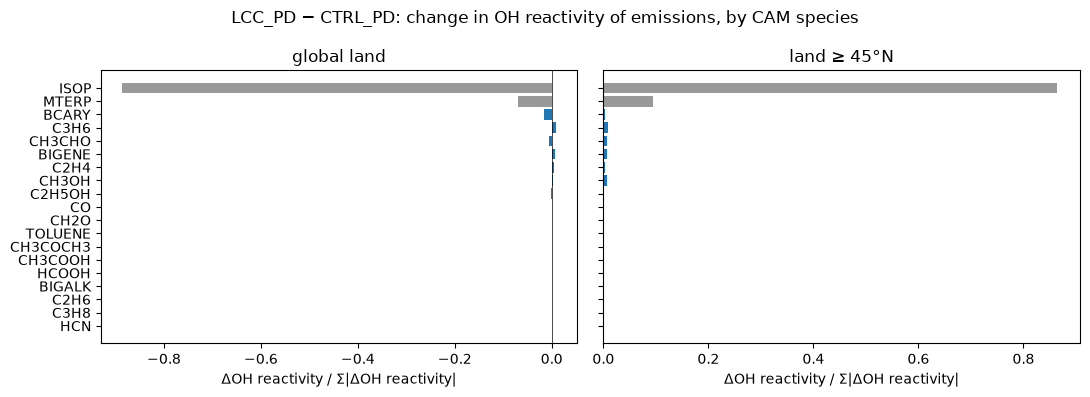

In [6]:
for ref, pert in PAIRS:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, domain in zip(axes, ("global", "region")):
        a, b = by_group(totals[ref], domain), by_group(totals[pert], domain)
        d = (b["OHR"] - a["OHR"]).groupby(a["cam"]).sum()
        d = d / (b["OHR"] - a["OHR"]).abs().sum()                # normalised: Σ|Δ| = 1
        d = d.reindex(d.abs().sort_values().index)
        ax.barh(d.index, d.values,
                color=["0.6" if c in ("ISOP", "MTERP") else "C0" for c in d.index])
        ax.axvline(0, color="k", lw=0.5)
        ax.set_title("global land" if domain == "global" else f"land ≥ {LAT_MIN_REGION:.0f}°N")
        ax.set_xlabel("ΔOH reactivity / Σ|ΔOH reactivity|")
    fig.suptitle(f"{pert} − {ref}: change in OH reactivity of emissions, by CAM species")
    fig.tight_layout()

## Key figure: what fBVOC removes vs. what LCC changes

Domain: land ≥ 45°N (where the land cover changes). Left: each group's share of CTRL emissions and of the LCC − CTRL change, by mass and by OH reactivity. Right: the change in OH reactivity, with the spread across years. The runs are nudged to the same winds, so each year of LCC is compared with the same year of CTRL.

The global domain is left out of this figure on purpose. There, ISOP and MTERP decrease while "Other" increases, so shares of the net change are not meaningful.

ΔOH reactivity, % of CTRL total (mean ± 2 SE over years):
ISOP     +3.29 ± 0.28
MTERP    +0.36 ± 0.05
Other    +0.15 ± 0.07


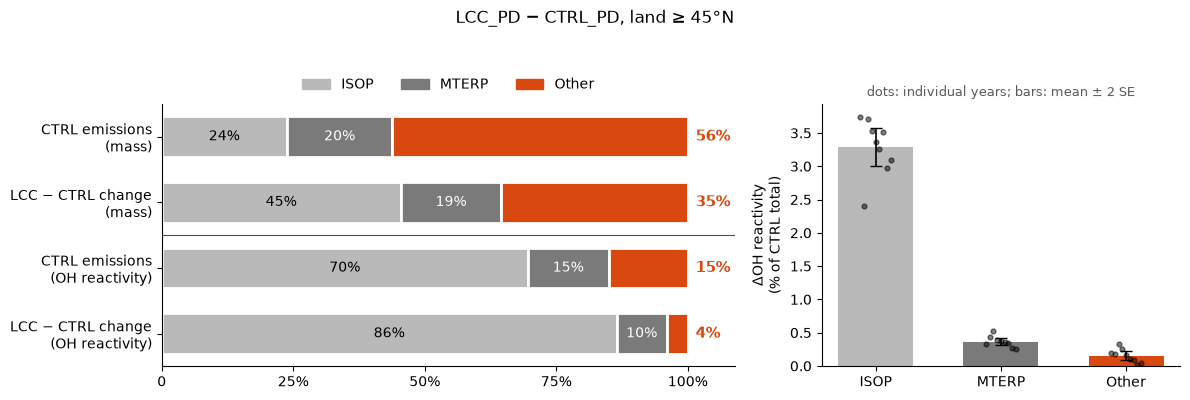

In [9]:
COL = {"ISOP": "#B9B9B9", "MTERP": "#7A7A7A", "Other": "#D9480F"}
GROUPS = ["ISOP", "MTERP", "Other"]

def yearly_by_group(alias, domain, metric):
    y = yearly[alias][domain]
    cam = pd.Series({n: COMPOUNDS[n][0] for n in y.columns})
    if metric == "OHR":
        y = y * 1e12 / pd.Series({n: COMPOUNDS[n][1] for n in y.columns}) * cam.map(K_OH)
    return y.T.groupby(cam.map(group)).sum().T[GROUPS]                  # years x group

def key_figure(ref, pert, domain="region"):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})

    # left: 100 % stacked shares
    rows = []
    for metric, mlabel in (("Tg", "mass"), ("OHR", "OH reactivity")):
        yr, yp = yearly_by_group(ref, domain, metric), yearly_by_group(pert, domain, metric)
        e, d = yr.mean(), (yp - yr).mean()
        rows += [(f"CTRL emissions\n({mlabel})", e), (f"LCC − CTRL change\n({mlabel})", d)]
    if any((r[1] < 0).any() for r in rows):
        print("Mixed signs in Δ: stacked shares not meaningful, see the right panel only.")
    labels = [r[0] for r in rows][::-1]
    for i, (_, v) in enumerate(rows[::-1]):
        frac, left = (v / v.sum()).clip(lower=0), 0.0
        for g in GROUPS:
            a1.barh(i, frac[g], left=left, height=0.62, color=COL[g],
                    edgecolor="white", linewidth=2)
            if g == "Other":                                             # always labelled, outside
                a1.text(1.015, i, f"{frac[g]:.0%}", ha="left", va="center",
                        fontsize=11, color=COL[g], fontweight="bold")
            elif frac[g] > 0.06:
                a1.text(left + frac[g] / 2, i, f"{frac[g]:.0%}", ha="center", va="center",
                        fontsize=10, color="white" if g != "ISOP" else "black")
            left += frac[g]
    a1.set_yticks(range(len(labels)), labels)
    a1.axhline(1.5, color="0.3", lw=0.8)
    a1.set_xlim(0, 1.09); a1.set_xticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
    a1.spines[["top", "right"]].set_visible(False)
    a1.legend([plt.Rectangle((0, 0), 1, 1, color=COL[g]) for g in GROUPS], GROUPS,
              ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)

    # right: ΔOHR per group as % of CTRL total OHR, with year-to-year spread
    yr, yp = yearly_by_group(ref, domain, "OHR"), yearly_by_group(pert, domain, "OHR")
    dd = (yp - yr).div(yr.sum(axis=1), axis=0) * 100                    # % of CTRL total, per year
    m, sem = dd.mean(), dd.std(ddof=1) / np.sqrt(len(dd))
    x = np.arange(len(GROUPS))
    a2.bar(x, m[GROUPS], color=[COL[g] for g in GROUPS], width=0.6)
    for xi, g in zip(x, GROUPS):
        a2.plot(np.full(len(dd), xi) + np.linspace(-.12, .12, len(dd)), dd[g], "o",
                ms=3.5, color="black", alpha=.5, zorder=3)
        a2.errorbar(xi, m[g], yerr=2 * sem[g], color="black", capsize=4, lw=1.2, zorder=4)
    a2.axhline(0, color="black", lw=0.6)
    a2.set_xticks(x, GROUPS)
    a2.set_ylabel("ΔOH reactivity\n(% of CTRL total)")
    a2.set_title("dots: individual years; bars: mean ± 2 SE", fontsize=9, color="0.35")
    a2.spines[["top", "right"]].set_visible(False)

    e_ohr = yearly_by_group(ref, domain, "OHR").mean()
    d_ohr = (yp - yr).mean()
    fig.suptitle(f"{pert} − {ref}, land ≥ {LAT_MIN_REGION:.0f}°N",#:  'Other' compounds are "
                 #f"{e_ohr['Other'] / e_ohr.sum():.0%} of emitted OH reactivity, but "
                 #f"{d_ohr['Other'] / d_ohr.sum():.0%} of its change", 
                 fontsize=12, y=1.04)
    fig.tight_layout()
    return fig, dd

for ref, pert in PAIRS:
    fig, dd = key_figure(ref, pert)
    print("ΔOH reactivity, % of CTRL total (mean ± 2 SE over years):")
    print((dd.mean().map("{:+.2f}".format) + " ± " + (2 * dd.std(ddof=1) / np.sqrt(len(dd))).map("{:.2f}".format)).to_string())

## How to read it

- **"Other" share of Δ is small by OH reactivity** (a few %): the BVOC contrast is effectively ISOP + MTERP for gas-phase chemistry.
- **It is not small:** the fBVOC runs remove a non-negligible chemical signal, and the D1 artifact needs to be quantified.
- **Aerosol:** in `chem_mech.in` the NorESM SOA reactions (`SOA_LV`, `SOA_SV`) use only MTERP and ISOP. So, if that is the mechanism your runs use, the "other" compounds affect aerosol only indirectly, through oxidants.

**Not covered here:**
- **Ozonolysis.** BCARY and MTERP also react with O₃; weighting by OH reactivity alone underweights BCARY.
- **Temperature.** k_OH is fixed at 298 K; at boreal temperatures the ratios shift somewhat.
- **Interannual noise.** The runs are nudged to the same meteorology, but this check does not test whether Δ is distinguishable from year-to-year variation.